SST, CHL NetCDF metadata verify for evidence sheet

In [ ]:
# ============================================================
# NETCDF PRODUCT METADATA & QUALITY-CONTROL AUDIT
# For SST and CHL
# ============================================================

import xarray as xr
import numpy as np
import pandas as pd
import os
import glob
import json
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 1. ENTER YOUR FILE PATHS HERE
# ============================================================

# ---- CHL ----
CHL_OLD = r"Copernicus_Chl-a_1997_2024.nc"
CHL_NEW = r"CHL_Complete_to_Jan2026.nc"

# ---- SST ----
SST_OLD = r"Merged_SST_2002_2025.nc"
SST_NEW = r"SST_Complete_to_Jan2026.nc"


# ============================================================
# 2. GENERAL HELPER FUNCTIONS
# ============================================================

def print_section(title):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)


def safe_min(da):
    try:
        return float(da.min(skipna=True).values)
    except:
        return "Not available"


def safe_max(da):
    try:
        return float(da.max(skipna=True).values)
    except:
        return "Not available"


def safe_mean(da):
    try:
        return float(da.mean(skipna=True).values)
    except:
        return "Not available"


def get_resolution(coord):
    """
    Estimate coordinate spacing for a 1-D latitude/longitude coordinate.
    """
    
    try:
        values = np.asarray(coord.values, dtype=float)
        
        if len(values) < 2:
            return None
        
        differences = np.diff(values)
        
        # Ignore unusual gaps
        differences = differences[np.isfinite(differences)]
        
        if len(differences) == 0:
            return None
        
        return float(np.median(np.abs(differences)))
    
    except:
        return None


def identify_coordinate(ds, possible_names):
    """
    Find a coordinate using several possible names.
    """
    
    for name in possible_names:
        if name in ds.coords:
            return name
        
        if name in ds.variables:
            return name
    
    return None


# ============================================================
# 3. MAIN METADATA FUNCTION
# ============================================================

def extract_netcdf_metadata(filepath, product_name="Unknown"):
    
    print_section(f"{product_name} — FILE INFORMATION")
    
    if not os.path.exists(filepath):
        print("FILE NOT FOUND:")
        print(filepath)
        return None
    
    # --------------------------------------------------------
    # Open dataset
    # --------------------------------------------------------
    
    ds = xr.open_dataset(filepath)
    
    print("File:")
    print(filepath)
    
    print("\nFile size:")
    print(round(os.path.getsize(filepath) / (1024**2), 3), "MB")
    
    
    # ========================================================
    # GLOBAL ATTRIBUTES
    # ========================================================
    
    print_section("GLOBAL ATTRIBUTES")
    
    if len(ds.attrs) == 0:
        print("No global attributes found.")
    else:
        for key, value in ds.attrs.items():
            print(f"{key}: {value}")
    
    
    # ========================================================
    # DATASET SUMMARY
    # ========================================================
    
    print_section("DATASET SUMMARY")
    
    print(ds)
    
    
    # ========================================================
    # DIMENSIONS
    # ========================================================
    
    print_section("DIMENSIONS")
    
    for dim, size in ds.sizes.items():
        print(f"{dim}: {size}")
    
    
    # ========================================================
    # COORDINATES
    # ========================================================
    
    print_section("COORDINATE INFORMATION")
    
    for coord_name in ds.coords:
        
        coord = ds[coord_name]
        
        print("\nCoordinate:", coord_name)
        print("Dimensions:", coord.dims)
        print("Shape:", coord.shape)
        print("Data type:", coord.dtype)
        
        # Attributes
        print("Attributes:")
        
        if len(coord.attrs) == 0:
            print("  None")
        else:
            for key, value in coord.attrs.items():
                print(f"  {key}: {value}")
        
        # Numeric coordinate information
        if np.issubdtype(coord.dtype, np.number):
            
            try:
                values = coord.values
            
                print("Minimum:", np.nanmin(values))
                print("Maximum:", np.nanmax(values))
                
                resolution = get_resolution(coord)
                
                if resolution is not None:
                    print("Approximate spacing:", resolution)
                    
            except:
                pass
        
        # Time coordinate
        if "time" in coord_name.lower():
            
            try:
                print("First time:", coord.values[0])
                print("Last time:", coord.values[-1])
                
                if len(coord.values) > 1:
                    print(
                        "Approximate time interval:",
                        coord.values[1] - coord.values[0]
                    )
                    
            except:
                pass
    
    
    # ========================================================
    # IDENTIFY LAT/LON
    # ========================================================
    
    print_section("SPATIAL COORDINATE IDENTIFICATION")
    
    lat_name = identify_coordinate(
        ds,
        ["lat", "latitude", "nav_lat", "y"]
    )
    
    lon_name = identify_coordinate(
        ds,
        ["lon", "longitude", "nav_lon", "x"]
    )
    
    print("Latitude coordinate:", lat_name)
    print("Longitude coordinate:", lon_name)
    
    
    # ========================================================
    # LAT/LON DETAILS
    # ========================================================
    
    if lat_name is not None and lon_name is not None:
        
        lat = ds[lat_name]
        lon = ds[lon_name]
        
        print_section("SPATIAL EXTENT AND RESOLUTION")
        
        try:
            print("Latitude minimum:", float(lat.min()))
            print("Latitude maximum:", float(lat.max()))
            
            print("Longitude minimum:", float(lon.min()))
            print("Longitude maximum:", float(lon.max()))
            
            print("Latitude spacing:", get_resolution(lat))
            print("Longitude spacing:", get_resolution(lon))
            
        except:
            print("Could not calculate spatial extent.")
    
    
    # ========================================================
    # TIME INFORMATION
    # ========================================================
    
    print_section("TIME INFORMATION")
    
    time_name = identify_coordinate(
        ds,
        ["time", "TIME", "Time"]
    )
    
    if time_name is not None:
        
        time = ds[time_name]
        
        try:
            print("Number of time records:", time.size)
            print("First time:", time.values[0])
            print("Last time:", time.values[-1])
            
            if time.size > 1:
                print(
                    "First interval:",
                    time.values[1] - time.values[0]
                )
                
        except Exception as e:
            print("Time information error:", e)
            
    else:
        print("No explicit time coordinate identified.")
    
    
    # ========================================================
    # DATA VARIABLES
    # ========================================================
    
    print_section("DATA VARIABLES")
    
    print("Variables:")
    
    for var_name in ds.data_vars:
        print(" -", var_name)
    
    
    # ========================================================
    # DETAILED VARIABLE INFORMATION
    # ========================================================
    
    print_section("DETAILED DATA-VARIABLE INFORMATION")
    
    variable_summary = []
    
    
    for var_name in ds.data_vars:
        
        da = ds[var_name]
        
        print("\n")
        print("-" * 70)
        print("VARIABLE:", var_name)
        print("-" * 70)
        
        print("Dimensions:", da.dims)
        print("Shape:", da.shape)
        print("Data type:", da.dtype)
        
        print("\nAttributes:")
        
        if len(da.attrs) == 0:
            print("  None")
        else:
            for key, value in da.attrs.items():
                print(f"  {key}: {value}")
        
        
        # ----------------------------------------------------
        # Statistical summary
        # ----------------------------------------------------
        
        print("\nBasic statistics:")
        
        print("Minimum:", safe_min(da))
        print("Maximum:", safe_max(da))
        print("Mean:", safe_mean(da))
        
        
        # ----------------------------------------------------
        # Missing values
        # ----------------------------------------------------
        
        try:
            total = da.size
            
            missing = int(
                da.isnull().sum().compute().values
                if hasattr(da.isnull().sum(), "compute")
                else da.isnull().sum().values
            )
            
            missing_percent = (
                missing / total * 100
                if total > 0 else np.nan
            )
            
            print("Total values:", total)
            print("Missing/NaN values:", missing)
            print(
                "Missing percentage:",
                round(missing_percent, 4),
                "%"
            )
            
        except Exception as e:
            print("Missing-data calculation unavailable:", e)
        
        
        # ----------------------------------------------------
        # Store summary
        # ----------------------------------------------------
        
        variable_summary.append({
            "product": product_name,
            "file": os.path.basename(filepath),
            "variable": var_name,
            "dimensions": str(da.dims),
            "shape": str(da.shape),
            "dtype": str(da.dtype),
            "units": da.attrs.get("units", ""),
            "standard_name": da.attrs.get("standard_name", ""),
            "long_name": da.attrs.get("long_name", ""),
            "min": safe_min(da),
            "max": safe_max(da),
            "mean": safe_mean(da),
            "fill_value": da.attrs.get("_FillValue", ""),
            "missing_value": da.attrs.get("missing_value", ""),
            "scale_factor": da.attrs.get("scale_factor", ""),
            "add_offset": da.attrs.get("add_offset", ""),
            "valid_min": da.attrs.get("valid_min", ""),
            "valid_max": da.attrs.get("valid_max", "")
        })
    
    
    # ========================================================
    # QUALITY CONTROL / FLAG VARIABLES
    # ========================================================
    
    print_section("QUALITY-CONTROL / FLAG VARIABLES")
    
    quality_keywords = [
        "quality",
        "qc",
        "flag",
        "mask",
        "cloud",
        "confidence",
        "status",
        "uncertainty",
        "error"
    ]
    
    possible_qc = []
    
    all_variables = list(ds.variables)
    
    for var_name in all_variables:
        
        lower_name = var_name.lower()
        
        if any(keyword in lower_name for keyword in quality_keywords):
            
            possible_qc.append(var_name)
            
            print("Possible QC/flag variable:", var_name)
            print("Dimensions:", ds[var_name].dims)
            print("Attributes:", ds[var_name].attrs)
    
    
    if len(possible_qc) == 0:
        print("No obvious QC/flag variable identified by name.")
    
    
    # ========================================================
    # CRS / PROJECTION
    # ========================================================
    
    print_section("CRS / PROJECTION INFORMATION")
    
    crs_found = False
    
    for var_name in ds.variables:
        
        attrs = ds[var_name].attrs
        
        for key in [
            "crs",
            "grid_mapping_name",
            "spatial_ref",
            "epsg_code",
            "proj4"
        ]:
            
            if key in attrs:
                
                crs_found = True
                
                print(
                    f"{var_name} -> {key}:",
                    attrs[key]
                )
    
    
    if not crs_found:
        print("No explicit CRS/projection information identified.")
    
    
    # ========================================================
    # PRODUCT / PROCESSING INFORMATION
    # ========================================================
    
    print_section("PRODUCT / PROCESSING INFORMATION")
    
    important_global_keywords = [
        "product",
        "dataset",
        "source",
        "institution",
        "creator",
        "provider",
        "processing",
        "version",
        "software",
        "algorithm",
        "platform",
        "sensor",
        "mission",
        "history",
        "license",
        "references"
    ]
    
    found = False
    
    for key, value in ds.attrs.items():
        
        key_lower = key.lower()
        
        if any(keyword in key_lower for keyword in important_global_keywords):
            
            print(f"{key}: {value}")
            found = True
    
    
    if not found:
        print("No obvious product/processing metadata identified.")
    
    
    # ========================================================
    # CLOSE DATASET
    # ========================================================
    
    ds.close()
    
    
    return pd.DataFrame(variable_summary)


# ============================================================
# 4. RUN THE AUDIT
# ============================================================

results = []


# ---- CHL OLD ----

chl_old_summary = extract_netcdf_metadata(
    CHL_OLD,
    product_name="CHL - Original/Older File"
)

if chl_old_summary is not None:
    results.append(chl_old_summary)


# ---- CHL NEW ----

chl_new_summary = extract_netcdf_metadata(
    CHL_NEW,
    product_name="CHL - Newer/Extended File"
)

if chl_new_summary is not None:
    results.append(chl_new_summary)


# ---- SST OLD ----

sst_old_summary = extract_netcdf_metadata(
    SST_OLD,
    product_name="SST - Original/Older File"
)

if sst_old_summary is not None:
    results.append(sst_old_summary)


# ---- SST NEW ----

sst_new_summary = extract_netcdf_metadata(
    SST_NEW,
    product_name="SST - Newer/Extended File"
)

if sst_new_summary is not None:
    results.append(sst_new_summary)


# ============================================================
# 5. COMBINE SUMMARIES
# ============================================================

if len(results) > 0:
    
    metadata_summary = pd.concat(
        results,
        ignore_index=True
    )
    
    print_section("COMBINED VARIABLE SUMMARY")
    
    display(metadata_summary)
    
else:
    
    print("No metadata were extracted.")

Checking the spatial maps of the problematic month CHL

In [4]:
# ============================================================
# CHL LOW-COVERAGE SPATIAL AUDIT
# Maps months with <20% ocean CHL coverage
# ============================================================

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from shapely.ops import unary_union
import os


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

CHL_FILE =r"My_CHL_FILE.nc"

OUTPUT_FOLDER = "CHL_Low_Coverage_Maps"

LAT_MIN = 20.5
LAT_MAX = 22.8
LON_MIN = 89.0
LON_MAX = 92.5

COVERAGE_THRESHOLD = 20


# ------------------------------------------------------------
# 2. CREATE OUTPUT FOLDER
# ------------------------------------------------------------

os.makedirs(OUTPUT_FOLDER, exist_ok=True)


# ------------------------------------------------------------
# 3. OPEN CHL DATA
# ------------------------------------------------------------

print("Opening CHL NetCDF...")

ds = xr.open_dataset(CHL_FILE)

chl = ds["CHL"]

# Make coordinates ascending
if chl.latitude[0] > chl.latitude[-1]:
    chl = chl.sortby("latitude")

if chl.longitude[0] > chl.longitude[-1]:
    chl = chl.sortby("longitude")


# ------------------------------------------------------------
# 4. SELECT STUDY AREA
# ------------------------------------------------------------

chl = chl.sel(
    latitude=slice(LAT_MIN, LAT_MAX),
    longitude=slice(LON_MIN, LON_MAX),
    time=slice("2002-08-01", "2026-01-01")
)

print("Study area selected.")
print(chl)


# ------------------------------------------------------------
# 5. CREATE GEOGRAPHIC OCEAN MASK
# ------------------------------------------------------------

print("\nCreating geographic ocean mask...")

land_feature = cfeature.NaturalEarthFeature(
    category="physical",
    name="land",
    scale="10m"
)

land_geometries = list(land_feature.geometries())

land_union = unary_union(land_geometries)

lats = chl.latitude.values
lons = chl.longitude.values

ocean_mask = np.zeros(
    (len(lats), len(lons)),
    dtype=bool
)

for i, lat in enumerate(lats):

    for j, lon in enumerate(lons):

        point = Point(float(lon), float(lat))

        ocean_mask[i, j] = not land_union.contains(point)


ocean_mask_xr = xr.DataArray(
    ocean_mask,
    coords={
        "latitude": lats,
        "longitude": lons
    },
    dims=["latitude", "longitude"]
)

ocean_cells = ocean_mask.sum()

print("Geographic ocean cells:", ocean_cells)


# ------------------------------------------------------------
# 6. FIND MONTHS WITH <20% OCEAN COVERAGE
# ------------------------------------------------------------

print("\nCalculating monthly coverage...")

monthly_records = []

for time_value in chl.time.values:

    monthly = chl.sel(time=time_value)

    ocean_chl = monthly.where(ocean_mask_xr)

    valid_cells = np.isfinite(ocean_chl.values).sum()

    coverage = valid_cells / ocean_cells * 100

    monthly_records.append({
        "Date": pd.Timestamp(time_value),
        "Valid_cells": valid_cells,
        "Coverage": coverage
    })


coverage_df = pd.DataFrame(monthly_records)


low_months = coverage_df[
    coverage_df["Coverage"] < COVERAGE_THRESHOLD
].copy()

print("\nLow-coverage months:")
print(low_months.to_string(index=False))


# ------------------------------------------------------------
# 7. CREATE MAP FOR EACH LOW-COVERAGE MONTH
# ------------------------------------------------------------
# ------------------------------------------------------------
# BETTER SPATIAL DIAGNOSTIC MAP
# ------------------------------------------------------------

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("\nCreating improved maps...")

for _, row in low_months.iterrows():

    date = row["Date"]
    coverage = row["Coverage"]

    monthly = chl.sel(time=date)

    valid_chl = np.isfinite(monthly.values)

    # --------------------------------------------------------
    # Classification:
    #
    # 0 = land
    # 1 = ocean + missing CHL
    # 2 = ocean + valid CHL
    # --------------------------------------------------------

    classification = np.zeros(
        ocean_mask.shape,
        dtype=int
    )

    classification[
        ocean_mask & (~valid_chl)
    ] = 1

    classification[
        ocean_mask & valid_chl
    ] = 2


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig = plt.figure(figsize=(10, 7))

    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    # 0 = land
    # 1 = missing ocean CHL
    # 2 = valid ocean CHL

    cmap = ListedColormap([
        "lightgray",
        "red",
        "blue"
    ])

    ax.pcolormesh(
        lons,
        lats,
        classification,
        cmap=cmap,
        vmin=0,
        vmax=2,
        shading="auto",
        transform=ccrs.PlateCarree()
    )

    # Coastline
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.8
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.5
    )

    # Gridlines
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        alpha=0.5
    )

    gl.top_labels = False
    gl.right_labels = False

    # Title
    ax.set_title(
        f"CHL spatial coverage — {date.strftime('%B %Y')}\n"
        f"Valid ocean CHL = {coverage:.2f}%",
        fontsize=13
    )

    # Legend
    legend_elements = [
        Patch(
            facecolor="lightgray",
            label="Land"
        ),
        Patch(
            facecolor="red",
            label="Ocean — CHL missing"
        ),
        Patch(
            facecolor="blue",
            label="Ocean — CHL valid"
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower left"
    )

    # Save
    filename = (
        f"CHL_Coverage_{date.strftime('%Y_%m')}.png"
    )

    filepath = os.path.join(
        OUTPUT_FOLDER,
        filename
    )

    plt.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print("Saved:", filepath)   

# ------------------------------------------------------------
# 8. SAVE LOW-COVERAGE LIST
# ------------------------------------------------------------

low_months.to_excel(
    os.path.join(
        OUTPUT_FOLDER,
        "Low_Coverage_Months.xlsx"
    ),
    index=False
)


print("\n======================================")
print("SPATIAL AUDIT COMPLETED")
print("Maps saved in:", OUTPUT_FOLDER)
print("Number of maps:", len(low_months))
print("======================================")

Opening CHL NetCDF...
Study area selected.
<xarray.DataArray 'CHL' (time: 282, latitude: 55, longitude: 84)> Size: 5MB
[1302840 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 2kB 2002-08-01 2002-09-01 ... 2026-01-01
  * latitude   (latitude) float32 220B 20.52 20.56 20.6 ... 22.69 22.73 22.77
  * longitude  (longitude) float32 336B 89.02 89.06 89.1 ... 92.4 92.44 92.48
Attributes:
    units:              milligram m-3
    standard_name:      mass_concentration_of_chlorophyll_a_in_sea_water
    long_name:          Chlorophyll-a concentration in seawater (not log-tran...
    source:             Orbview-2/SeaStar-SeaWiFS-L3
    type:               surface
    units_nonstandard:  mg m^-3
    valid_max:          66.83439
    valid_min:          0.01

Creating geographic ocean mask...
Geographic ocean cells: 2968

Calculating monthly coverage...

Low-coverage months:
      Date  Valid_cells  Coverage
2003-06-01          305 10.276280
2012-05-01          385 12.9

PermissionError: [Errno 13] Permission denied: 'CHL_Low_Coverage_Maps\\Low_Coverage_Months.xlsx'

Sensitivity check up for CHL NC file to choose minimum threshold to make final dataset

INPUT_NC = r"D:\Publication\data\NetCDF4_data\chl\total\CHL_Complete_to_Jan2026.nc"

OUTPUT_FOLDER = (
    r"E:\Regional_Studies_Marine\Revision\Data\Sensitivity_analysis"


CHL COVERAGE SENSITIVITY ANALYSIS

Input file:
D:\Publication\data\NetCDF4_data\chl\total\CHL_Complete_to_Jan2026.nc

Output directory:
E:\Regional_Studies_Marine\Revision\Data\Sensitivity_analysis

------------------------------------------------------------
Opening NetCDF dataset...
------------------------------------------------------------
<xarray.Dataset> Size: 312MB
Dimensions:    (time: 340, latitude: 443, longitude: 518)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1997-10-01 1997-11-01 ... 2026-01-01
  * latitude   (latitude) float32 2kB 6.062 6.104 6.146 ... 24.4 24.44 24.48
  * longitude  (longitude) float32 2kB 78.15 78.19 78.23 ... 99.6 99.65 99.69
Data variables:
    CHL        (time, latitude, longitude) float32 312MB ...
Attributes:
    Conventions:       CF-1.11
    title:             c3s_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M
    institution:       Plymouth Marine Laboratory, operating as a production ...
    contact:           email: cmems@pml.ac.uk
 

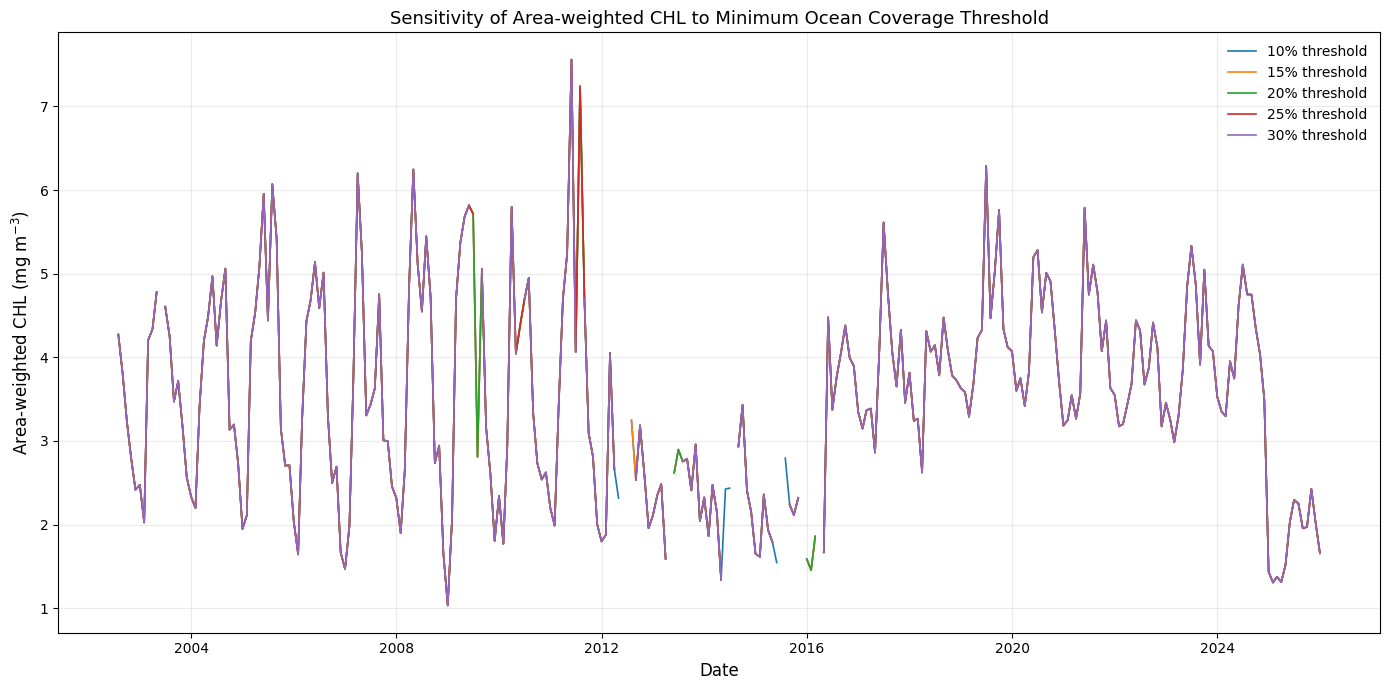


ANALYSIS COMPLETED

Study period: 2002-08-01 to 2026-01-31
Expected months: 282
Actual months: 282
Ocean cells: 3207
Thresholds tested: [10, 15, 20, 25, 30]

Excel output:
E:\Regional_Studies_Marine\Revision\Data\Sensitivity_analysis\CHL_Coverage_Sensitivity_Analysis.xlsx

Figure output:
E:\Regional_Studies_Marine\Revision\Data\Sensitivity_analysis\CHL_Coverage_Threshold_Sensitivity.png

NOTE

The trend values in the sensitivity summary are descriptive
linear trends used only to compare the effect of the different
coverage thresholds.

They are not the final autocorrelation-corrected trend tests
for the manuscript.

After selecting the final coverage threshold, the corresponding
CHL dataset should be frozen and used for the subsequent
preprocessing and statistical reanalysis.



In [10]:
# ============================================================
# CHL COVERAGE THRESHOLD SENSITIVITY ANALYSIS
#
# Study period: August 2002 – January 2026
# Study area: 20.5–22.8°N, 89.0–92.5°E
#
# Coverage thresholds:
# 10%, 15%, 20%, 25%, 30%
#
# Purpose:
# To examine how different minimum CHL coverage thresholds
# affect the area-weighted monthly CHL time series.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import linregress
import regionmask

warnings.filterwarnings("ignore")


# ============================================================
# 2. USER SETTINGS
# ============================================================

# ------------------------------------------------------------
# INPUT NETCDF FILE
# ------------------------------------------------------------

INPUT_NC = (
    r"CHL_Complete_to_Jan2026.nc"
)


# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = (
    r"\Sensitivity_analysis"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# OUTPUT FILES
# ------------------------------------------------------------

OUTPUT_EXCEL = os.path.join(
    OUTPUT_DIR,
    "CHL_Coverage_Sensitivity_Analysis.xlsx"
)

OUTPUT_FIGURE = os.path.join(
    OUTPUT_DIR,
    "CHL_Coverage_Threshold_Sensitivity.png"
)


# ------------------------------------------------------------
# STUDY PERIOD
# ------------------------------------------------------------

STUDY_START = "2002-08-01"
STUDY_END = "2026-01-31"

EXPECTED_MONTHS = 282


# ------------------------------------------------------------
# STUDY AREA
# ------------------------------------------------------------

LAT_MIN = 20.5
LAT_MAX = 22.8

LON_MIN = 89.0
LON_MAX = 92.5


# ------------------------------------------------------------
# VARIABLE NAMES
# ------------------------------------------------------------

CHL_VARIABLE = "CHL"

TIME_NAME = "time"
LAT_NAME = "latitude"
LON_NAME = "longitude"


# ------------------------------------------------------------
# COVERAGE THRESHOLDS
# ------------------------------------------------------------

THRESHOLDS = [
    10,
    15,
    20,
    25,
    30
]


# ============================================================
# 3. CHECK INPUT FILE
# ============================================================

print("\n============================================================")
print("CHL COVERAGE SENSITIVITY ANALYSIS")
print("============================================================")

print("\nInput file:")
print(INPUT_NC)

print("\nOutput directory:")
print(OUTPUT_DIR)


if not os.path.exists(INPUT_NC):

    raise FileNotFoundError(
        "\nNetCDF file not found:\n"
        f"{INPUT_NC}\n\n"
        "Please change INPUT_NC to the correct NetCDF file."
    )


# ============================================================
# 4. OPEN NETCDF
# ============================================================

print("\n------------------------------------------------------------")
print("Opening NetCDF dataset...")
print("------------------------------------------------------------")

ds = xr.open_dataset(
    INPUT_NC
)

print(ds)


# ============================================================
# 5. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    CHL_VARIABLE,
    TIME_NAME,
    LAT_NAME,
    LON_NAME
]


for var in required_variables:

    if var not in ds:

        raise KeyError(
            f"\nRequired variable/coordinate "
            f"'{var}' was not found in the NetCDF file.\n\n"
            f"Available variables/coordinates:\n"
            f"{list(ds.variables)}"
        )


# ============================================================
# 6. CHECK AND SORT COORDINATES
# ============================================================

print("\n------------------------------------------------------------")
print("Checking coordinate order...")
print("------------------------------------------------------------")


# Latitude
if not np.all(
    np.diff(
        ds[LAT_NAME].values
    ) > 0
):

    print(
        "Latitude is not ascending."
    )

    print(
        "Sorting latitude..."
    )

    ds = ds.sortby(
        LAT_NAME
    )


# Longitude
if not np.all(
    np.diff(
        ds[LON_NAME].values
    ) > 0
):

    print(
        "Longitude is not ascending."
    )

    print(
        "Sorting longitude..."
    )

    ds = ds.sortby(
        LON_NAME
    )


# Time
ds = ds.sortby(
    TIME_NAME
)


# ============================================================
# 7. SPATIAL SUBSET
# ============================================================

print("\n------------------------------------------------------------")
print("Applying spatial subset...")
print("------------------------------------------------------------")

print(
    f"Latitude: {LAT_MIN} to {LAT_MAX}"
)

print(
    f"Longitude: {LON_MIN} to {LON_MAX}"
)


ds_area = ds.sel(
    {
        LAT_NAME: slice(
            LAT_MIN,
            LAT_MAX
        ),

        LON_NAME: slice(
            LON_MIN,
            LON_MAX
        )
    }
)


# ============================================================
# 8. TEMPORAL SUBSET
# ============================================================

print("\n------------------------------------------------------------")
print("Applying study-period subset...")
print("------------------------------------------------------------")

print(
    f"Study period: "
    f"{STUDY_START} to {STUDY_END}"
)


# ONLY the requested study period is retained.
ds_area = ds_area.sel(
    {
        TIME_NAME: slice(
            STUDY_START,
            STUDY_END
        )
    }
)


# ============================================================
# 9. EXTRACT CHL
# ============================================================

chl = ds_area[
    CHL_VARIABLE
]


# ============================================================
# 10. STUDY PERIOD VERIFICATION
# ============================================================

dates_all = pd.to_datetime(
    chl[TIME_NAME].values
)


print("\n------------------------------------------------------------")
print("Study-period verification")
print("------------------------------------------------------------")


if len(dates_all) == 0:

    raise ValueError(
        "\nNo CHL data were found within the requested "
        "study period."
    )


print(
    "First month:",
    dates_all[0]
)

print(
    "Last month:",
    dates_all[-1]
)

print(
    "Number of months:",
    len(dates_all)
)


if len(dates_all) != EXPECTED_MONTHS:

    raise ValueError(
        "\nStudy-period month check failed.\n"
        f"Expected {EXPECTED_MONTHS} months for "
        "August 2002–January 2026, "
        f"but found {len(dates_all)} months."
    )


# ============================================================
# 11. CHECK MONTHLY CONTINUITY
# ============================================================

expected_months = pd.period_range(
    start="2002-08",
    end="2026-01",
    freq="M"
)


actual_months = dates_all.to_period(
    "M"
)


missing_months = (
    expected_months
    .difference(
        actual_months
    )
)


duplicate_months = (
    actual_months[
        actual_months.duplicated()
    ]
)


if len(missing_months) > 0:

    print(
        "\nWARNING: Missing calendar months:"
    )

    for month in missing_months:

        print(
            month
        )

else:

    print(
        "\nMonthly continuity check: PASSED"
    )


if len(duplicate_months) > 0:

    print(
        "\nWARNING: Duplicate months detected:"
    )

    for month in duplicate_months:

        print(
            month
        )

else:

    print(
        "Duplicate-month check: PASSED"
    )


# ============================================================
# 12. FINAL DATA DIMENSIONS
# ============================================================

print("\n------------------------------------------------------------")
print("Final study-period CHL dataset")
print("------------------------------------------------------------")

print(chl)


n_time = chl.sizes[
    TIME_NAME
]

n_lat = chl.sizes[
    LAT_NAME
]

n_lon = chl.sizes[
    LON_NAME
]


total_grid_cells = (
    n_lat *
    n_lon
)


print(
    "\nNumber of months:",
    n_time
)

print(
    "Latitude cells:",
    n_lat
)

print(
    "Longitude cells:",
    n_lon
)

print(
    "Total rectangular grid cells:",
    total_grid_cells
)


# ============================================================
# 13. CREATE NATURAL EARTH OCEAN MASK
# ============================================================

print("\n------------------------------------------------------------")
print("Creating geographic ocean mask...")
print("------------------------------------------------------------")


lat = chl[
    LAT_NAME
].values


lon = chl[
    LON_NAME
].values


# Create 2-D longitude/latitude grids
lon_grid, lat_grid = np.meshgrid(
    lon,
    lat
)


# Natural Earth land polygons
land_regions = (
    regionmask
    .defined_regions
    .natural_earth_v5_0_0
    .land_110
)


# Create land mask
land_mask_da = land_regions.mask(
    lon_grid,
    lat_grid
)


land_mask = ~np.isnan(
    land_mask_da.values
)


# Ocean mask
ocean_mask = ~land_mask


# ============================================================
# 14. OCEAN CELL COUNT
# ============================================================

n_land_cells = int(
    land_mask.sum()
)

n_ocean_cells = int(
    ocean_mask.sum()
)


print(
    "\nGeographic land cells:",
    n_land_cells
)

print(
    "Geographic ocean cells:",
    n_ocean_cells
)

print(
    "Total cells:",
    total_grid_cells
)

print(
    "Ocean percentage:",
    round(
        100 *
        n_ocean_cells /
        total_grid_cells,
        2
    ),
    "%"
)


# ============================================================
# 15. CONVERT OCEAN MASK TO XARRAY
# ============================================================

ocean_mask_da = xr.DataArray(
    ocean_mask,
    coords={
        LAT_NAME: lat,
        LON_NAME: lon
    },
    dims=[
        LAT_NAME,
        LON_NAME
    ]
)


# ============================================================
# 16. APPLY OCEAN MASK
# ============================================================

chl_ocean = chl.where(
    ocean_mask_da
)


# ============================================================
# 17. CREATE COSINE-LATITUDE WEIGHTS
# ============================================================

lat_weights = xr.DataArray(
    np.cos(
        np.deg2rad(lat)
    ),
    coords={
        LAT_NAME: lat
    },
    dims=[
        LAT_NAME
    ]
)


# ============================================================
# 18. AREA-WEIGHTED CHL FUNCTION
# ============================================================

def area_weighted_chl(
    chl_data,
    coverage_threshold,
    ocean_mask,
    weights,
    dates
):

    """
    Calculate monthly area-weighted CHL after applying
    a minimum ocean-cell coverage threshold.
    """

    results = []


    # Number of geographic ocean cells
    total_ocean_cells = int(
        ocean_mask.sum()
    )


    # --------------------------------------------------------
    # Loop through every month
    # --------------------------------------------------------

    for i, date in enumerate(dates):

        # Select one monthly CHL field
        monthly_chl = chl_data.isel(
            {
                TIME_NAME: i
            }
        )


        # ----------------------------------------------------
        # Valid CHL pixels
        # ----------------------------------------------------

        valid_mask = (
            np.isfinite(
                monthly_chl.values
            )
            &
            ocean_mask
        )


        valid_cells = int(
            valid_mask.sum()
        )


        # ----------------------------------------------------
        # Coverage percentage
        # ----------------------------------------------------

        coverage_pct = (
            100.0
            *
            valid_cells
            /
            total_ocean_cells
        )


        # ----------------------------------------------------
        # Apply coverage threshold
        # ----------------------------------------------------

        if coverage_pct >= coverage_threshold:

            # Keep valid ocean CHL
            monthly_valid = monthly_chl.where(
                np.isfinite(
                    monthly_chl
                )
                &
                ocean_mask_da
            )


            # ------------------------------------------------
            # Area-weighted numerator
            # ------------------------------------------------

            weighted_sum = (
                monthly_valid
                *
                weights
            ).sum(
                dim=[
                    LAT_NAME,
                    LON_NAME
                ],
                skipna=True
            )


            # ------------------------------------------------
            # Area-weighted denominator
            # ------------------------------------------------

            weight_sum = (
                weights
                .where(
                    np.isfinite(
                        monthly_valid
                    )
                )
            ).sum(
                dim=[
                    LAT_NAME,
                    LON_NAME
                ],
                skipna=True
            )


            # Convert xarray scalars to float
            weighted_sum_value = float(
                weighted_sum
            )

            weight_sum_value = float(
                weight_sum
            )


            # ------------------------------------------------
            # Calculate weighted mean
            # ------------------------------------------------

            if (
                np.isfinite(
                    weight_sum_value
                )
                and
                weight_sum_value > 0
            ):

                chl_mean = (
                    weighted_sum_value
                    /
                    weight_sum_value
                )

            else:

                chl_mean = np.nan


        else:

            # Month fails coverage criterion
            chl_mean = np.nan


        # ----------------------------------------------------
        # Save monthly result
        # ----------------------------------------------------

        results.append(
            {
                "Date":
                    date,

                "Month-Year":
                    date.strftime(
                        "%b-%Y"
                    ),

                "CHL (mg/m^3)":
                    chl_mean,

                "Ocean cells":
                    total_ocean_cells,

                "Valid CHL cells":
                    valid_cells,

                "Coverage (%)":
                    coverage_pct,

                "Included":
                    coverage_pct
                    >=
                    coverage_threshold
            }
        )


    return pd.DataFrame(
        results
    )


# ============================================================
# 19. SIMPLE DESCRIPTIVE TREND FUNCTION
# ============================================================

def calculate_simple_trend(
    df
):

    """
    Calculate a simple linear trend.

    This trend is ONLY used to compare the effect of
    different coverage thresholds.

    It is NOT the final autocorrelation-corrected
    trend analysis for the manuscript.
    """


    # Keep months with valid CHL
    valid = df[
        df[
            "CHL (mg/m^3)"
        ].notna()
    ].copy()


    # Need at least two observations
    if len(valid) < 2:

        return {
            "N":
                len(valid),

            "Trend (mg/m^3/year)":
                np.nan,

            "Trend p-value":
                np.nan
        }


    # Convert dates to NumPy datetime array
    dates = pd.to_datetime(
        valid["Date"]
    ).to_numpy()


    # CHL values
    values = valid[
        "CHL (mg/m^3)"
    ].to_numpy(
        dtype=float
    )


    # --------------------------------------------------------
    # IMPORTANT ROBUST DATE CONVERSION
    #
    # Convert elapsed days directly using NumPy.
    # This avoids both:
    #     .days
    # and
    #     .dt.days
    # errors.
    # --------------------------------------------------------

    time_days = (
        dates -
        dates[0]
    ) / np.timedelta64(
        1,
        "D"
    )


    # Convert days to years
    time_years = (
        time_days /
        365.25
    )


    # --------------------------------------------------------
    # Linear regression
    # --------------------------------------------------------

    regression = linregress(
        time_years,
        values
    )


    return {
        "N":
            len(valid),

        "Trend (mg/m^3/year)":
            regression.slope,

        "Trend p-value":
            regression.pvalue
    }


# ============================================================
# 20. RUN THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

print("\n============================================================")
print("RUNNING COVERAGE THRESHOLD SENSITIVITY")
print("============================================================")


threshold_results = {}

summary_rows = []


for threshold in THRESHOLDS:

    print("\n------------------------------------------------------------")

    print(
        f"Processing {threshold}% coverage threshold..."
    )

    print("------------------------------------------------------------")


    # Calculate threshold-specific CHL series
    df_threshold = area_weighted_chl(
        chl_data=chl_ocean,
        coverage_threshold=threshold,
        ocean_mask=ocean_mask,
        weights=lat_weights,
        dates=dates_all
    )


    # Store result
    threshold_results[
        threshold
    ] = df_threshold


    # --------------------------------------------------------
    # Month counts
    # --------------------------------------------------------

    total_months = len(
        df_threshold
    )


    retained_months = int(
        df_threshold[
            "Included"
        ].sum()
    )


    excluded_months = (
        total_months
        -
        retained_months
    )


    # --------------------------------------------------------
    # Descriptive statistics
    # --------------------------------------------------------

    valid_chl = (
        df_threshold[
            "CHL (mg/m^3)"
        ]
        .dropna()
    )


    if len(valid_chl) > 0:

        mean_chl = (
            valid_chl.mean()
        )

        median_chl = (
            valid_chl.median()
        )

        sd_chl = (
            valid_chl.std(
                ddof=1
            )
        )

        min_chl = (
            valid_chl.min()
        )

        max_chl = (
            valid_chl.max()
        )

    else:

        mean_chl = np.nan
        median_chl = np.nan
        sd_chl = np.nan
        min_chl = np.nan
        max_chl = np.nan


    # --------------------------------------------------------
    # Simple descriptive trend
    # --------------------------------------------------------

    trend_info = calculate_simple_trend(
        df_threshold
    )


    # --------------------------------------------------------
    # Summary row
    # --------------------------------------------------------

    summary_rows.append(
        {

            "Coverage threshold (%)":
                threshold,

            "Total months":
                total_months,

            "Retained months":
                retained_months,

            "Excluded months":
                excluded_months,

            "Mean CHL (mg/m^3)":
                mean_chl,

            "Median CHL (mg/m^3)":
                median_chl,

            "SD CHL (mg/m^3)":
                sd_chl,

            "Minimum CHL (mg/m^3)":
                min_chl,

            "Maximum CHL (mg/m^3)":
                max_chl,

            "Trend (mg/m^3/year)":
                trend_info[
                    "Trend (mg/m^3/year)"
                ],

            "Trend p-value":
                trend_info[
                    "Trend p-value"
                ]
        }
    )


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print(
        "Total months:",
        total_months
    )

    print(
        "Retained months:",
        retained_months
    )

    print(
        "Excluded months:",
        excluded_months
    )

    print(
        "Mean CHL:",
        f"{mean_chl:.4f}"
    )

    print(
        "Median CHL:",
        f"{median_chl:.4f}"
    )

    print(
        "SD CHL:",
        f"{sd_chl:.4f}"
    )

    print(
        "Minimum CHL:",
        f"{min_chl:.4f}"
    )

    print(
        "Maximum CHL:",
        f"{max_chl:.4f}"
    )

    print(
        "Trend:",
        f"{trend_info['Trend (mg/m^3/year)']:.6f}"
    )

    print(
        "Trend p-value:",
        f"{trend_info['Trend p-value']:.6f}"
    )


# ============================================================
# 21. CREATE SUMMARY DATAFRAME
# ============================================================

summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# 22. CREATE EXCLUDED-MONTH TABLE
# ============================================================

excluded_rows = []


for threshold in THRESHOLDS:

    df_threshold = threshold_results[
        threshold
    ]


    excluded = df_threshold[
        ~df_threshold[
            "Included"
        ]
    ].copy()


    for _, row in excluded.iterrows():

        excluded_rows.append(
            {

                "Coverage threshold (%)":
                    threshold,

                "Date":
                    row["Date"],

                "Month-Year":
                    row["Month-Year"],

                "Coverage (%)":
                    row["Coverage (%)"],

                "Valid CHL cells":
                    row[
                        "Valid CHL cells"
                    ]
            }
        )


excluded_df = pd.DataFrame(
    excluded_rows
)


# ============================================================
# 23. PRINT SUMMARY
# ============================================================

print("\n============================================================")
print("SENSITIVITY SUMMARY")
print("============================================================")

print(
    summary_df.to_string(
        index=False
    )
)


# ============================================================
# 24. SAVE EXCEL WORKBOOK
# ============================================================

print("\n------------------------------------------------------------")
print("Writing Excel workbook...")
print("------------------------------------------------------------")


with pd.ExcelWriter(
    OUTPUT_EXCEL,
    engine="openpyxl"
) as writer:

    # --------------------------------------------------------
    # Summary sheet
    # --------------------------------------------------------

    summary_df.to_excel(
        writer,
        sheet_name="Sensitivity_Summary",
        index=False
    )


    # --------------------------------------------------------
    # Individual threshold sheets
    # --------------------------------------------------------

    for threshold in THRESHOLDS:

        df_threshold = threshold_results[
            threshold
        ].copy()


        output_df = df_threshold[
            [
                "Month-Year",
                "CHL (mg/m^3)",
                "Coverage (%)",
                "Valid CHL cells",
                "Ocean cells",
                "Included"
            ]
        ]


        sheet_name = (
            f"Threshold_{threshold}pct"
        )


        output_df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )


    # --------------------------------------------------------
    # Excluded months sheet
    # --------------------------------------------------------

    if len(excluded_df) > 0:

        excluded_df.to_excel(
            writer,
            sheet_name="Excluded_Months",
            index=False
        )


print(
    "\nExcel file successfully saved:"
)

print(
    OUTPUT_EXCEL
)

# ============================================================
# 25. CREATE COMPARISON FIGURE
# ============================================================

print("\n------------------------------------------------------------")
print("Creating comparison figure...")
print("------------------------------------------------------------")


plt.figure(
    figsize=(14, 7)
)


for threshold in THRESHOLDS:

    df_threshold = threshold_results[
        threshold
    ]

    plt.plot(
        df_threshold["Date"],
        df_threshold["CHL (mg/m^3)"],
        linewidth=1.2,
        label=f"{threshold}% threshold"
    )


plt.xlabel(
    "Date",
    fontsize=12
)

plt.ylabel(
    "Area-weighted CHL (mg m$^{-3}$)",
    fontsize=12
)

plt.title(
    "Sensitivity of Area-weighted CHL "
    "to Minimum Ocean Coverage Threshold",
    fontsize=13
)

plt.legend(
    frameon=False
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

try:

    # Make sure output directory exists
    os.makedirs(
        OUTPUT_DIR,
        exist_ok=True
    )

    # Use an absolute path
    figure_path = os.path.abspath(
        OUTPUT_FIGURE
    )

    print(
        "\nSaving figure to:"
    )

    print(
        figure_path
    )

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        format="png"
    )

    print(
        "\nFigure successfully saved."
    )

except OSError as e:

    print(
        "\nWARNING: Could not save the figure "
        "to the specified folder."
    )

    print(
        "Error:",
        e
    )

    # Continue displaying the figure instead of stopping
    # the entire sensitivity analysis.

plt.show()

plt.close()

# ============================================================
# 26. FINAL CHECK
# ============================================================

print("\n============================================================")
print("ANALYSIS COMPLETED")
print("============================================================")


print(
    "\nStudy period:",
    f"{STUDY_START} to {STUDY_END}"
)


print(
    "Expected months:",
    EXPECTED_MONTHS
)


print(
    "Actual months:",
    len(dates_all)
)


print(
    "Ocean cells:",
    n_ocean_cells
)


print(
    "Thresholds tested:",
    THRESHOLDS
)


print(
    "\nExcel output:"
)

print(
    OUTPUT_EXCEL
)


print(
    "\nFigure output:"
)

print(
    OUTPUT_FIGURE
)


print("\n============================================================")
print("NOTE")
print("============================================================")

print(
    """
The trend values in the sensitivity summary are descriptive
linear trends used only to compare the effect of the different
coverage thresholds.

They are not the final autocorrelation-corrected trend tests
for the manuscript.

After selecting the final coverage threshold, the corresponding
CHL dataset should be frozen and used for the subsequent
preprocessing and statistical reanalysis.
"""
)

16 months excluded at 25% and the spatial maps, because that will give us the final scientific check: are those 16 months genuinely poor spatial observations, or are some of them legitimate but spatially localized coastal events?

In [1]:
# ============================================================
# CHL SPATIAL COVERAGE AUDIT
# 25% MINIMUM OCEAN-CELL COVERAGE
#
# Purpose:
#   1. Identify months with <25% valid CHL coverage
#      among geographic ocean cells.
#   2. Generate one spatial map for every excluded month.
#   3. Generate a 4 × 4 overview figure.
#   4. Save the excluded-month information to Excel.
#
# Map classification:
#   Gray = Land
#   Red  = Ocean + missing CHL
#   Blue = Ocean + valid CHL
#
# IMPORTANT:
#   This script uses the ORIGINAL monthly CHL values.
#   No interpolation, anomaly calculation, detrending,
#   log transformation, or standardization is performed.
# ============================================================


# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import regionmask


# ============================================================
# 2. USER SETTINGS
# ============================================================

# ------------------------------------------------------------
# CHANGE THESE THREE PATHS ONLY
# ------------------------------------------------------------

INPUT_NETCDF = "CHL_Complete_to_Jan2026.nc"

OUTPUT_DIR = "Sensitivity_analysis"

OUTPUT_EXCEL = os.path.join(
    OUTPUT_DIR,
    "CHL_25pct_Excluded_Months.xlsx"
)


# ------------------------------------------------------------
# Study area
# ------------------------------------------------------------

LAT_MIN = 20.5
LAT_MAX = 22.8

LON_MIN = 89.0
LON_MAX = 92.5


# ------------------------------------------------------------
# Study period
# ------------------------------------------------------------

START_DATE = "2002-08-01"
END_DATE = "2026-01-31"


# ------------------------------------------------------------
# Minimum valid ocean-cell coverage
# ------------------------------------------------------------

COVERAGE_THRESHOLD = 25.0


# ------------------------------------------------------------
# Expected number of ocean cells
#
# Based on the previous Natural Earth cell-center mask:
#   Total cells = 55 × 84 = 4620
#   Ocean cells = 2968
#
# This is only a consistency check.
# ------------------------------------------------------------

EXPECTED_OCEAN_CELLS = 2968


# ------------------------------------------------------------
# Figure settings
# ------------------------------------------------------------

INDIVIDUAL_FIGSIZE = (10, 7)

OVERVIEW_FIGSIZE = (16, 14)

DPI = 300


# ============================================================
# 3. CREATE OUTPUT DIRECTORY
# ============================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("CHL SPATIAL COVERAGE AUDIT")
print("=" * 70)

print("\nInput file:")
print(os.path.abspath(INPUT_NETCDF))

print("\nOutput directory:")
print(os.path.abspath(OUTPUT_DIR))


# ============================================================
# 4. CHECK INPUT FILE
# ============================================================

if not os.path.isfile(INPUT_NETCDF):
    raise FileNotFoundError(
        f"\nInput NetCDF file was not found:\n{INPUT_NETCDF}\n\n"
        "Please check the INPUT_NETCDF path."
    )


# ============================================================
# 5. OPEN NETCDF DATASET
# ============================================================

print("\n" + "=" * 70)
print("Opening NetCDF dataset...")
print("=" * 70)

ds = xr.open_dataset(INPUT_NETCDF)

print("\nDataset dimensions:")
print(ds.dims)

print("\nDataset variables:")
print(list(ds.data_vars))

print("\nDataset coordinates:")
print(list(ds.coords))


# ============================================================
# 6. AUTOMATICALLY IDENTIFY CHL VARIABLE
# ============================================================

# The primary Copernicus variable is expected to be CHL.
# ESA CCI commonly uses chlor_a.
#
# We check both so that the script is less likely to fail
# simply because the variable name differs.

if "CHL" in ds.data_vars:
    chl_name = "CHL"

elif "chlor_a" in ds.data_vars:
    chl_name = "chlor_a"

else:
    raise KeyError(
        "\nCould not find a CHL variable.\n"
        "Expected either 'CHL' or 'chlor_a'.\n"
        f"Available variables: {list(ds.data_vars)}"
    )

print(f"\nCHL variable selected: {chl_name}")


# ============================================================
# 7. AUTOMATICALLY IDENTIFY COORDINATES
# ============================================================

# Time
if "time" in ds.coords:
    time_name = "time"
else:
    raise KeyError(
        "Could not find the 'time' coordinate."
    )


# Latitude
if "latitude" in ds.coords:
    lat_name = "latitude"

elif "lat" in ds.coords:
    lat_name = "lat"

else:
    raise KeyError(
        "\nCould not identify latitude coordinate.\n"
        "Expected either 'latitude' or 'lat'."
    )


# Longitude
if "longitude" in ds.coords:
    lon_name = "longitude"

elif "lon" in ds.coords:
    lon_name = "lon"

else:
    raise KeyError(
        "\nCould not identify longitude coordinate.\n"
        "Expected either 'longitude' or 'lon'."
    )


print(f"Time coordinate      : {time_name}")
print(f"Latitude coordinate  : {lat_name}")
print(f"Longitude coordinate : {lon_name}")


# ============================================================
# 8. CHECK CHL DIMENSIONS
# ============================================================

chl = ds[chl_name]

print("\nCHL dimensions:")
print(chl.dims)

print("\nCHL shape:")
print(chl.shape)

expected_dimensions = {
    time_name,
    lat_name,
    lon_name
}

if not expected_dimensions.issubset(set(chl.dims)):
    raise ValueError(
        "\nCHL variable does not contain the expected "
        "time/latitude/longitude dimensions.\n"
        f"CHL dimensions: {chl.dims}"
    )


# ============================================================
# 9. SORT COORDINATES
# ============================================================

# Sorting avoids problems if latitude or longitude are stored
# in descending order.

ds = ds.sortby(lat_name)
ds = ds.sortby(lon_name)
ds = ds.sortby(time_name)

chl = ds[chl_name]


# ============================================================
# 10. SELECT STUDY AREA
# ============================================================

print("\n" + "=" * 70)
print("Selecting study area...")
print("=" * 70)

chl_region = chl.sel(
    {
        lat_name: slice(LAT_MIN, LAT_MAX),
        lon_name: slice(LON_MIN, LON_MAX)
    }
)


print("\nStudy-area CHL shape:")
print(chl_region.shape)

print(
    f"Latitude range : "
    f"{float(chl_region[lat_name].min()):.4f} – "
    f"{float(chl_region[lat_name].max()):.4f}"
)

print(
    f"Longitude range: "
    f"{float(chl_region[lon_name].min()):.4f} – "
    f"{float(chl_region[lon_name].max()):.4f}"
)


# ============================================================
# 11. SELECT STUDY PERIOD
# ============================================================

print("\n" + "=" * 70)
print("Selecting study period...")
print("=" * 70)

chl_region = chl_region.sel(
    {
        time_name: slice(
            START_DATE,
            END_DATE
        )
    }
)


n_months = chl_region.sizes[time_name]

print(f"\nNumber of monthly observations: {n_months}")

if n_months != 282:
    warnings.warn(
        f"\nExpected 282 months for August 2002–January 2026, "
        f"but found {n_months} months."
    )


# ============================================================
# 12. VERIFY MONTHLY TIME SERIES
# ============================================================

time_values = pd.to_datetime(
    chl_region[time_name].values
)

print("\nFirst month:")
print(time_values[0])

print("\nLast month:")
print(time_values[-1])

print("\nNumber of unique months:")
print(
    time_values.to_period("M").nunique()
)


# ============================================================
# 13. CREATE NATURAL EARTH LAND/OCEAN MASK
# ============================================================

print("\n" + "=" * 70)
print("Creating Natural Earth land/ocean mask...")
print("=" * 70)


# Extract coordinates
lat = chl_region[lat_name].values
lon = chl_region[lon_name].values


# Create 2-D coordinate grid
lon_grid, lat_grid = np.meshgrid(
    lon,
    lat
)


# Natural Earth land polygons
land_regions = (
    regionmask
    .defined_regions
    .natural_earth_v5_0_0
    .land_110
)


# Generate land mask
land_mask_da = land_regions.mask(
    lon_grid,
    lat_grid
)


# Convert to NumPy array
land_mask = ~np.isnan(
    land_mask_da.values
)


# Ocean mask
ocean_mask = ~land_mask


# ============================================================
# 14. REPORT GRID INFORMATION
# ============================================================

n_lat = len(lat)
n_lon = len(lon)

total_cells = n_lat * n_lon

n_land = np.sum(land_mask)

n_ocean = np.sum(ocean_mask)


print("\nGrid information:")
print(f"Latitude cells  : {n_lat}")
print(f"Longitude cells : {n_lon}")
print(f"Total cells     : {total_cells}")
print(f"Land cells      : {n_land}")
print(f"Ocean cells     : {n_ocean}")


# Consistency check
if n_ocean != EXPECTED_OCEAN_CELLS:

    warnings.warn(
        "\nWARNING:\n"
        f"The script found {n_ocean} ocean cells, "
        f"whereas the previous analysis found "
        f"{EXPECTED_OCEAN_CELLS} ocean cells.\n\n"
        "This may indicate that the input grid or mask differs "
        "from the dataset used in the original sensitivity analysis."
    )

else:

    print(
        "\nOcean-cell count matches the previous analysis: "
        f"{EXPECTED_OCEAN_CELLS}"
    )


# ============================================================
# 15. EXTRACT CHL AS NUMPY ARRAY
# ============================================================

chl_values = np.asarray(
    chl_region.values
)


print("\nCHL NumPy array shape:")
print(chl_values.shape)


# Expected shape:
# (time, latitude, longitude)

if chl_values.ndim != 3:
    raise ValueError(
        "\nExpected CHL array to have exactly 3 dimensions "
        "(time, latitude, longitude).\n"
        f"Found shape: {chl_values.shape}"
    )


# ============================================================
# 16. CALCULATE MONTHLY OCEAN-CELL COVERAGE
# ============================================================

print("\n" + "=" * 70)
print("Calculating monthly ocean-cell coverage...")
print("=" * 70)


coverage_records = []


for i, current_time in enumerate(time_values):

    # CHL field for one month
    monthly_chl = chl_values[i, :, :]


    # Valid CHL = finite numerical value
    valid_chl = np.isfinite(
        monthly_chl
    )


    # Only ocean cells are considered
    valid_ocean = (
        valid_chl
        & ocean_mask
    )


    # Count valid ocean cells
    valid_cells = int(
        np.sum(valid_ocean)
    )


    # Coverage percentage
    if n_ocean > 0:

        coverage_pct = (
            valid_cells
            / n_ocean
            * 100.0
        )

    else:

        coverage_pct = np.nan


    coverage_records.append(
        {
            "Date": current_time,
            "Year": current_time.year,
            "Month": current_time.month,
            "Month_Name": current_time.strftime("%B"),
            "Valid_Ocean_Cells": valid_cells,
            "Total_Ocean_Cells": int(n_ocean),
            "Coverage_Percent": coverage_pct
        }
    )


# Convert to DataFrame
coverage_df = pd.DataFrame(
    coverage_records
)


# ============================================================
# 17. IDENTIFY MONTHS BELOW 25%
# ============================================================

excluded_df = coverage_df[
    coverage_df["Coverage_Percent"]
    < COVERAGE_THRESHOLD
].copy()


excluded_df = excluded_df.sort_values(
    "Date"
).reset_index(
    drop=True
)


# ============================================================
# 18. PRINT COVERAGE SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("COVERAGE SUMMARY")
print("=" * 70)

print(
    f"\nCoverage threshold: "
    f"{COVERAGE_THRESHOLD:.1f}%"
)

print(
    f"Total months: "
    f"{len(coverage_df)}"
)

print(
    f"Retained months: "
    f"{len(coverage_df) - len(excluded_df)}"
)

print(
    f"Excluded months: "
    f"{len(excluded_df)}"
)


# ============================================================
# 19. PRINT EXCLUDED MONTHS
# ============================================================

print("\nMonths excluded at the 25% threshold:")
print("-" * 70)

if len(excluded_df) == 0:

    print("No months were excluded.")

else:

    for _, row in excluded_df.iterrows():

        print(
            f"{row['Date'].strftime('%Y-%m')}  |  "
            f"{row['Month_Name']:>9}  |  "
            f"{row['Coverage_Percent']:.2f}% coverage  |  "
            f"{row['Valid_Ocean_Cells']} valid / "
            f"{row['Total_Ocean_Cells']} ocean cells"
        )


# ============================================================
# 20. CHECK EXPECTED NUMBER OF EXCLUDED MONTHS
# ============================================================

if len(excluded_df) != 16:

    warnings.warn(
        "\nThe script did not identify exactly 16 excluded months.\n"
        f"Expected: 16\n"
        f"Found   : {len(excluded_df)}\n\n"
        "This may indicate that the input NetCDF, spatial mask, "
        "or study-period selection differs from the dataset used "
        "for the original 25% sensitivity analysis."
    )

else:

    print(
        "\nConfirmed: exactly 16 months are excluded "
        "at the 25% threshold."
    )


# ============================================================
# 21. CREATE MAP COLORMAP
# ============================================================

# Classification:
#
# 0 = Land
# 1 = Ocean + missing CHL
# 2 = Ocean + valid CHL

map_colors = [
    "lightgray",
    "red",
    "blue"
]


classification_cmap = ListedColormap(
    map_colors
)


# ============================================================
# 22. CREATE LEGEND
# ============================================================

legend_elements = [

    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="Land"
    ),

    Patch(
        facecolor="red",
        edgecolor="black",
        label="Ocean + missing CHL"
    ),

    Patch(
        facecolor="blue",
        edgecolor="black",
        label="Ocean + valid CHL"
    )

]


# ============================================================
# 23. FUNCTION TO CREATE CLASSIFICATION MAP
# ============================================================

def create_classification_array(
    monthly_chl,
    ocean_mask
):
    """
    Create a classification array.

    Values:
        0 = land
        1 = ocean + missing CHL
        2 = ocean + valid CHL
    """

    # Start everything as land
    classification = np.zeros(
        monthly_chl.shape,
        dtype=np.int8
    )


    # Ocean cells
    classification[ocean_mask] = 1


    # Valid CHL over ocean
    valid_ocean = (
        ocean_mask
        & np.isfinite(monthly_chl)
    )


    classification[valid_ocean] = 2


    return classification


# ============================================================
# 24. FUNCTION TO PLOT ONE MONTH
# ============================================================

def plot_single_month(
    monthly_chl,
    current_time,
    coverage_pct,
    output_path
):
    """
    Create and save one monthly CHL coverage map.
    """

    classification = create_classification_array(
        monthly_chl,
        ocean_mask
    )


    fig, ax = plt.subplots(
        figsize=INDIVIDUAL_FIGSIZE
    )


    # Plot classification
    mesh = ax.pcolormesh(
        lon,
        lat,
        classification,
        cmap=classification_cmap,
        vmin=-0.5,
        vmax=2.5,
        shading="auto"
    )


    # Study-area extent
    ax.set_xlim(
        LON_MIN,
        LON_MAX
    )

    ax.set_ylim(
        LAT_MIN,
        LAT_MAX
    )


    # Axis labels
    ax.set_xlabel(
        "Longitude (°E)",
        fontsize=12
    )

    ax.set_ylabel(
        "Latitude (°N)",
        fontsize=12
    )


    # Title
    title_text = (
        f"{current_time.strftime('%B %Y')} "
        f"— CHL coverage: {coverage_pct:.2f}%"
    )

    ax.set_title(
        title_text,
        fontsize=14,
        fontweight="bold",
        pad=12
    )


    # Grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.4
    )


    # Legend
    ax.legend(
        handles=legend_elements,
        loc="upper right",
        fontsize=9,
        frameon=True
    )


    # Small annotation
    ax.text(
        0.02,
        0.02,
        "25% minimum coverage threshold",
        transform=ax.transAxes,
        fontsize=9,
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            alpha=0.8
        )
    )


    # Save
    fig.savefig(
        output_path,
        dpi=DPI,
        format="png",
        bbox_inches="tight"
    )


    plt.close(fig)


# ============================================================
# 25. CREATE INDIVIDUAL MAPS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING INDIVIDUAL MAPS")
print("=" * 70)


individual_map_paths = []


for _, row in excluded_df.iterrows():

    current_time = pd.Timestamp(
        row["Date"]
    )


    # Find corresponding time index
    matching_indices = np.where(
        time_values == current_time
    )[0]


    if len(matching_indices) == 0:

        warnings.warn(
            f"Could not find CHL data for "
            f"{current_time.strftime('%Y-%m')}."
        )

        continue


    time_index = matching_indices[0]


    # Monthly CHL field
    monthly_chl = chl_values[
        time_index,
        :, :
    ]


    # Safe filename
    filename = (
        f"CHL_Excluded_"
        f"{current_time.strftime('%Y-%m')}.png"
    )


    output_path = os.path.join(
        OUTPUT_DIR,
        filename
    )


    # Create map
    plot_single_month(
        monthly_chl=monthly_chl,
        current_time=current_time,
        coverage_pct=row["Coverage_Percent"],
        output_path=output_path
    )


    individual_map_paths.append(
        output_path
    )


    print(
        f"Saved: {filename} "
        f"({row['Coverage_Percent']:.2f}% coverage)"
    )


# ============================================================
# 26. CREATE 4 × 4 OVERVIEW FIGURE
# ============================================================

print("\n" + "=" * 70)
print("GENERATING 4 × 4 OVERVIEW MAP")
print("=" * 70)


n_excluded = len(excluded_df)


# Always use 4 × 4 because the expected number is 16
n_rows = 4
n_cols = 4


fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=OVERVIEW_FIGSIZE
)


# Convert axes to flat array
axes = np.asarray(
    axes
).flatten()


for panel_index, (_, row) in enumerate(
    excluded_df.iterrows()
):

    ax = axes[panel_index]


    current_time = pd.Timestamp(
        row["Date"]
    )


    # Find time index
    matching_indices = np.where(
        time_values == current_time
    )[0]


    if len(matching_indices) == 0:

        ax.axis("off")

        continue


    time_index = matching_indices[0]


    # Monthly CHL
    monthly_chl = chl_values[
        time_index,
        :, :
    ]


    # Classification
    classification = create_classification_array(
        monthly_chl,
        ocean_mask
    )


    # Plot
    ax.pcolormesh(
        lon,
        lat,
        classification,
        cmap=classification_cmap,
        vmin=-0.5,
        vmax=2.5,
        shading="auto"
    )


    # Extent
    ax.set_xlim(
        LON_MIN,
        LON_MAX
    )

    ax.set_ylim(
        LAT_MIN,
        LAT_MAX
    )


    # Title
    ax.set_title(
        f"{current_time.strftime('%b %Y')}\n"
        f"Coverage = {row['Coverage_Percent']:.2f}%",
        fontsize=11,
        fontweight="bold"
    )


    # Grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.4,
        alpha=0.4
    )


    # Axis labels
    ax.set_xlabel(
        "Longitude (°E)",
        fontsize=9
    )

    ax.set_ylabel(
        "Latitude (°N)",
        fontsize=9
    )


# Hide unused panels if any
for i in range(
    n_excluded,
    len(axes)
):

    axes[i].axis("off")


# Overall title
fig.suptitle(
    "CHL Spatial Coverage for Months Excluded at 25% Ocean-Cell Threshold",
    fontsize=17,
    fontweight="bold",
    y=0.995
)


# Shared legend
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=11,
    frameon=True,
    bbox_to_anchor=(0.5, 0.01)
)


# Adjust layout
plt.tight_layout(
    rect=[
        0,
        0.05,
        1,
        0.97
    ]
)


# Overview output
overview_path = os.path.join(
    OUTPUT_DIR,
    "CHL_25pct_Excluded_Months_Overview.png"
)


fig.savefig(
    overview_path,
    dpi=DPI,
    format="png",
    bbox_inches="tight"
)


plt.close(fig)


print(
    f"\nOverview saved:\n{overview_path}"
)


# ============================================================
# 27. CREATE EXCLUDED-MONTH EXCEL FILE
# ============================================================

print("\n" + "=" * 70)
print("SAVING COVERAGE TABLES")
print("=" * 70)


# Make a clean copy
excluded_output = excluded_df.copy()


# Format date
excluded_output["Date"] = (
    pd.to_datetime(
        excluded_output["Date"]
    ).dt.strftime("%Y-%m-%d")
)


# Round coverage
excluded_output[
    "Coverage_Percent"
] = excluded_output[
    "Coverage_Percent"
].round(4)


# Save Excel with two sheets
with pd.ExcelWriter(
    OUTPUT_EXCEL,
    engine="openpyxl"
) as writer:

    # Sheet 1: excluded months
    excluded_output.to_excel(
        writer,
        sheet_name="Excluded_Months",
        index=False
    )


    # Sheet 2: all monthly coverage
    all_coverage_output = coverage_df.copy()


    all_coverage_output["Date"] = (
        pd.to_datetime(
            all_coverage_output["Date"]
        ).dt.strftime("%Y-%m-%d")
    )


    all_coverage_output[
        "Coverage_Percent"
    ] = all_coverage_output[
        "Coverage_Percent"
    ].round(4)


    all_coverage_output.to_excel(
        writer,
        sheet_name="All_Months_Coverage",
        index=False
    )


print(
    f"\nExcel file saved:\n{OUTPUT_EXCEL}"
)


# ============================================================
# 28. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ANALYSIS COMPLETED")
print("=" * 70)

print(
    f"\nStudy period: "
    f"{time_values[0].strftime('%B %Y')} "
    f"to "
    f"{time_values[-1].strftime('%B %Y')}"
)

print(
    f"Total months analyzed: "
    f"{len(coverage_df)}"
)

print(
    f"Ocean cells: "
    f"{n_ocean}"
)

print(
    f"Coverage threshold: "
    f"{COVERAGE_THRESHOLD:.1f}%"
)

print(
    f"Excluded months: "
    f"{len(excluded_df)}"
)

print(
    f"Retained months: "
    f"{len(coverage_df) - len(excluded_df)}"
)

print(
    f"\nIndividual maps saved in:\n"
    f"{os.path.abspath(OUTPUT_DIR)}"
)

print(
    f"\nOverview figure:\n"
    f"{os.path.abspath(overview_path)}"
)

print(
    f"\nCoverage Excel file:\n"
    f"{os.path.abspath(OUTPUT_EXCEL)}"
)


# ============================================================
# 29. PRINT FINAL EXCLUDED-MONTH LIST
# ============================================================

print("\n" + "=" * 70)
print("FINAL EXCLUDED MONTH LIST")
print("=" * 70)

for i, (_, row) in enumerate(
    excluded_df.iterrows(),
    start=1
):

    print(
        f"{i:02d}. "
        f"{pd.Timestamp(row['Date']).strftime('%B %Y')} "
        f"— "
        f"{row['Coverage_Percent']:.2f}%"
    )


print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

CHL SPATIAL COVERAGE AUDIT

Input file:
D:\Publication\data\NetCDF4_data\chl\total\CHL_Complete_to_Jan2026.nc

Output directory:
E:\Regional_Studies_Marine\Revision\Data\Sensitivity_analysis

Opening NetCDF dataset...

Dataset dimensions:
FrozenMappingWarningOnValuesAccess({'time': 340, 'latitude': 443, 'longitude': 518})

Dataset variables:
['CHL']

Dataset coordinates:
['time', 'latitude', 'longitude']

CHL variable selected: CHL
Time coordinate      : time
Latitude coordinate  : latitude
Longitude coordinate : longitude

CHL dimensions:
('time', 'latitude', 'longitude')

CHL shape:
(340, 443, 518)

Selecting study area...

Study-area CHL shape:
(340, 55, 84)
Latitude range : 20.5208 – 22.7708
Longitude range: 89.0208 – 92.4792

Selecting study period...

Number of monthly observations: 282

First month:
2002-08-01 00:00:00

Last month:
2026-01-01 00:00:00

Number of unique months:
282

Creating Natural Earth land/ocean mask...

Grid information:
Latitude cells  : 55
Longitude cells 

C:\Users\HP\AppData\Local\Temp\ipykernel_10852\1956932021.py:423: UserWarning: 
The script found 3207 ocean cells, whereas the previous analysis found 2968 ocean cells.

This may indicate that the input grid or mask differs from the dataset used in the original sensitivity analysis.
  warnings.warn(



CHL NumPy array shape:
(282, 55, 84)

Calculating monthly ocean-cell coverage...

COVERAGE SUMMARY

Coverage threshold: 25.0%
Total months: 282
Retained months: 266
Excluded months: 16

Months excluded at the 25% threshold:
----------------------------------------------------------------------
2003-06  |       June  |  9.14% coverage  |  293 valid / 3207 ocean cells
2009-08  |     August  |  21.20% coverage  |  680 valid / 3207 ocean cells
2012-05  |        May  |  11.91% coverage  |  382 valid / 3207 ocean cells
2012-06  |       June  |  0.22% coverage  |  7 valid / 3207 ocean cells
2012-07  |       July  |  0.59% coverage  |  19 valid / 3207 ocean cells
2012-08  |     August  |  17.87% coverage  |  573 valid / 3207 ocean cells
2013-05  |        May  |  4.93% coverage  |  158 valid / 3207 ocean cells
2013-07  |       July  |  22.64% coverage  |  726 valid / 3207 ocean cells
2014-06  |       June  |  14.25% coverage  |  457 valid / 3207 ocean cells
2014-08  |     August  |  4.30% cove